<a href="https://colab.research.google.com/github/DarkDreamz-38/AI-Lab/blob/main/(Lab%203)_Different_Machine_Learning_Models_Applied_to_the_Processed_Stroke_Dataset_and_do_the_Comparative_Study_among_ML_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q imbalanced-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SklearnPipeline

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStroke Distribution:")
print(df['stroke'].value_counts())

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Dataset Loaded Successfully!
Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB
None

Missing Values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_

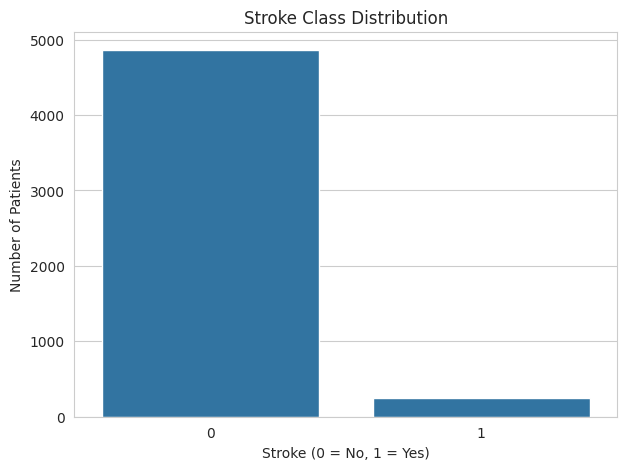

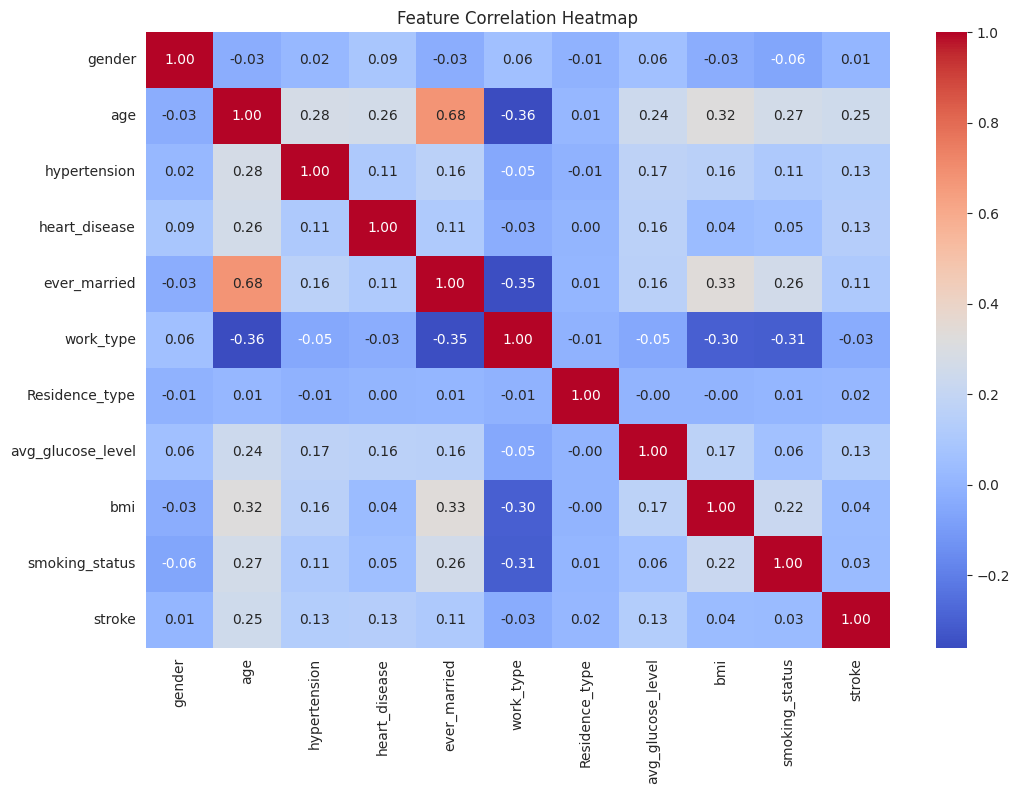

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='stroke')

plt.title("Stroke Class Distribution")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [ ]:
X = df.drop('stroke', axis=1)
y = df['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nOriginal Training Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())

Training samples: 4088
Testing samples: 1022

Original Training Distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing Distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel='rbf',
        probability=True,
        random_state=42,
        class_weight='balanced'
    ),

    "ANN": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
}

print("Five ML models defined successfully!")

Five ML models defined successfully!


In [ ]:
trained_models = {}
results = {}
roc_data = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', model)
    ])

    print(f"\nTraining {name}...")

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'AUC-ROC': roc_auc_score(y_test, y_prob)
    }

    roc_data[name] = {
        'y_pred': y_pred,
        'y_prob': y_prob,
        'fpr': roc_curve(y_test, y_prob)[0],
        'tpr': roc_curve(y_test, y_prob)[1],
        'auc': roc_auc_score(y_test, y_prob)
    }

    print(f"{name} trained successfully!")

print("\nAll five models trained successfully!")


Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training SVM...
SVM trained successfully!

Training ANN...
ANN trained successfully!

All five models trained successfully!


In [ ]:
performance_df = pd.DataFrame(results).T

performance_df = performance_df.sort_values(
    by='AUC-ROC',
    ascending=False
)

print("MODEL PERFORMANCE COMPARISON")

display(
    performance_df.style.format("{:.4f}").highlight_max(
        color='lightgreen'
    )
)

MODEL PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Logistic Regression,0.7613,0.1460,0.8000,0.2469,0.8381
Random Forest,0.9266,0.1622,0.1200,0.1379,0.7864
SVM,0.7671,0.1179,0.5800,0.1959,0.7762
ANN,0.8757,0.1333,0.2800,0.1806,0.7664
Decision Tree,0.8943,0.1184,0.1800,0.1429,0.5555


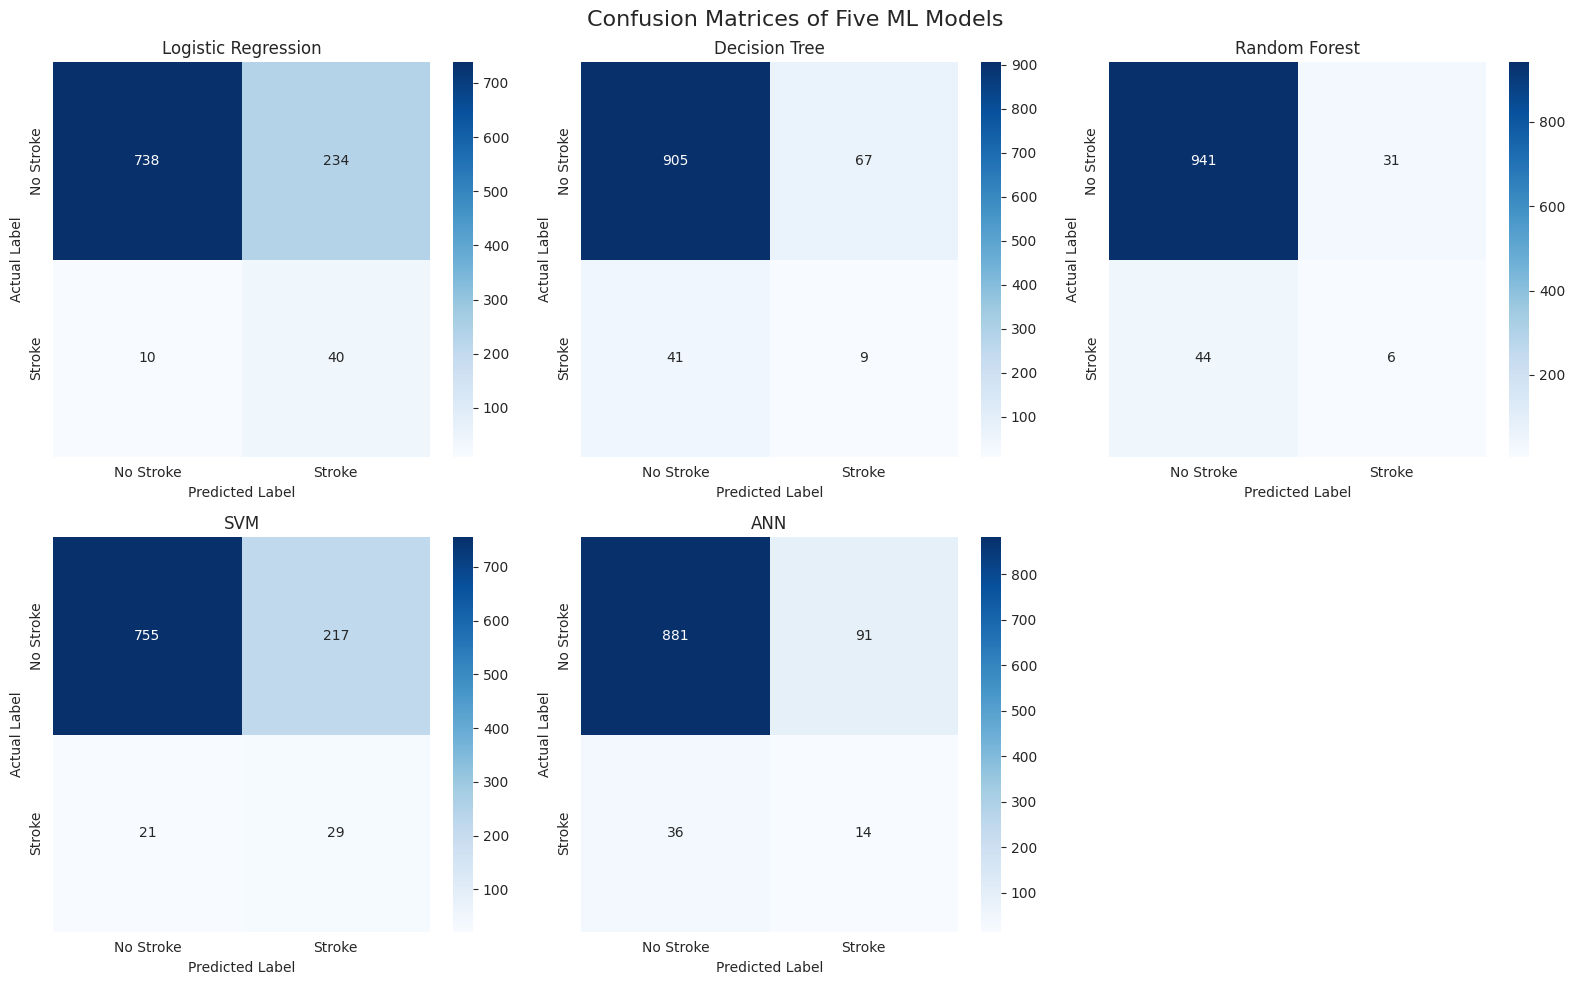

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, (name, data) in enumerate(roc_data.items()):

    cm = confusion_matrix(y_test, data['y_pred'])

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i],
        xticklabels=['No Stroke', 'Stroke'],
        yticklabels=['No Stroke', 'Stroke']
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

axes[5].axis('off')

plt.suptitle(
    "Confusion Matrices of Five ML Models",
    fontsize=16
)

plt.tight_layout()
plt.show()

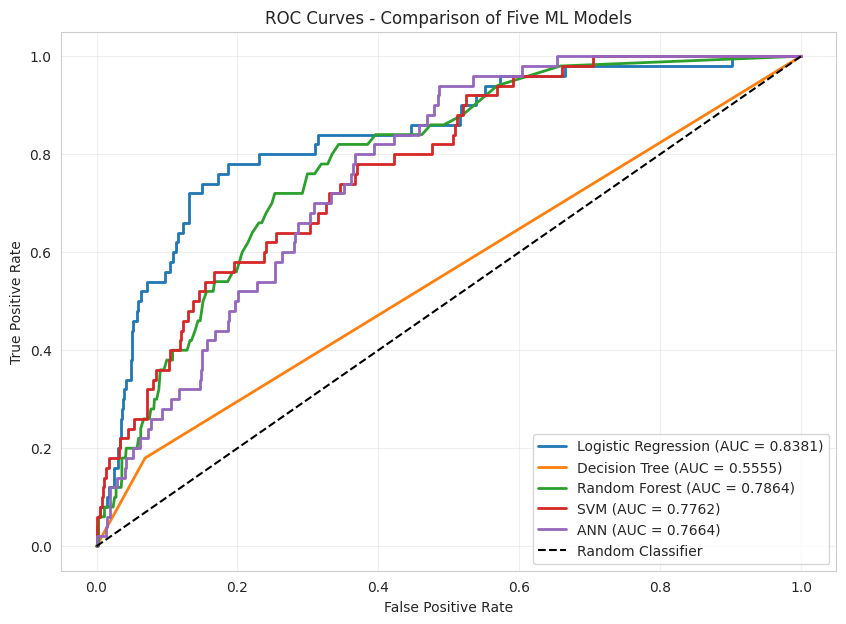

In [ ]:
plt.figure(figsize=(10, 7))

for name, data in roc_data.items():

    plt.plot(
        data['fpr'],
        data['tpr'],
        linewidth=2,
        label=f"{name} (AUC = {data['auc']:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Random Classifier'
)

plt.title("ROC Curves - Comparison of Five ML Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()

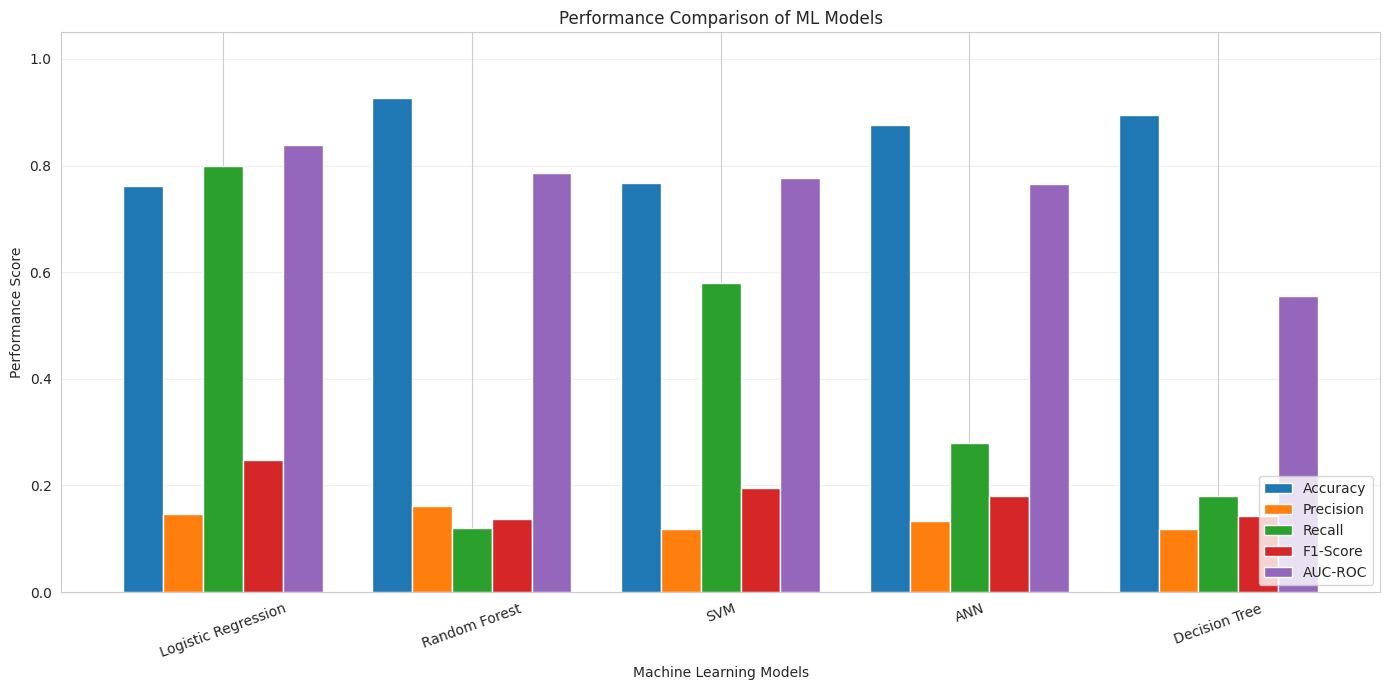

In [ ]:
performance_df.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title("Performance Comparison of ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")

plt.xticks(rotation=20)
plt.ylim(0, 1.05)

plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
ranking_df = performance_df.copy()

ranking_df['Recall Rank'] = ranking_df['Recall'].rank(
    ascending=False,
    method='min'
)

ranking_df['F1 Rank'] = ranking_df['F1-Score'].rank(
    ascending=False,
    method='min'
)

ranking_df['AUC Rank'] = ranking_df['AUC-ROC'].rank(
    ascending=False,
    method='min'
)

ranking_df['Average Rank'] = ranking_df[
    ['Recall Rank', 'F1 Rank', 'AUC Rank']
].mean(axis=1)

ranking_df = ranking_df.sort_values(
    'Average Rank'
)

top_3_models = ranking_df.head(3)

print("TOP 3 MACHINE LEARNING MODELS")

display(top_3_models)

TOP 3 MACHINE LEARNING MODELS


,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Recall Rank,F1 Rank,AUC Rank,Average Rank
Logistic Regression,0.761252,0.145985,0.80,0.246914,0.838066,1.0,1.0,1.0,1.000000
SVM,0.767123,0.117886,0.58,0.195946,0.776235,2.0,2.0,3.0,2.333333
ANN,0.875734,0.133333,0.28,0.180645,0.766358,3.0,3.0,4.0,3.333333


In [ ]:
risk_analysis = []

for name in top_3_models.index:

    data = roc_data[name]

    cm = confusion_matrix(
        y_test,
        data['y_pred']
    )

    tn, fp, fn, tp = cm.ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0

    risk_analysis.append({
        'Model': name,
        'True Positive': tp,
        'True Negative': tn,
        'False Positive': fp,
        'False Negative': fn,
        'Sensitivity': recall_score(y_test, data['y_pred']),
        'Specificity': specificity,
        'Precision': precision_score(
            y_test, data['y_pred'], zero_division=0
        ),
        'F1-Score': f1_score(
            y_test, data['y_pred'], zero_division=0
        ),
        'AUC-ROC': data['auc']
    })

risk_df = pd.DataFrame(risk_analysis)

print("TOP 3 MODELS - STROKE RISK ANALYSIS")

display(
    risk_df.style.format({
        'Sensitivity': '{:.4f}',
        'Specificity': '{:.4f}',
        'Precision': '{:.4f}',
        'F1-Score': '{:.4f}',
        'AUC-ROC': '{:.4f}'
    })
)

TOP 3 MODELS - STROKE RISK ANALYSIS


,Model,True Positive,True Negative,False Positive,False Negative,Sensitivity,Specificity,Precision,F1-Score,AUC-ROC
0,Logistic Regression,40,738,234,10,0.8000,0.7593,0.1460,0.2469,0.8381
1,SVM,29,755,217,21,0.5800,0.7767,0.1179,0.1959,0.7762
2,ANN,14,881,91,36,0.2800,0.9064,0.1333,0.1806,0.7664


In [ ]:
for name in top_3_models.index:

    print("\n" + "=" * 60)
    print("CLASSIFICATION REPORT:", name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            roc_data[name]['y_pred'],
            target_names=['No Stroke', 'Stroke'],
            zero_division=0
        )
    )


CLASSIFICATION REPORT: Logistic Regression
              precision    recall  f1-score   support

   No Stroke       0.99      0.76      0.86       972
      Stroke       0.15      0.80      0.25        50

    accuracy                           0.76      1022
   macro avg       0.57      0.78      0.55      1022
weighted avg       0.95      0.76      0.83      1022


CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

   No Stroke       0.97      0.78      0.86       972
      Stroke       0.12      0.58      0.20        50

    accuracy                           0.77      1022
   macro avg       0.55      0.68      0.53      1022
weighted avg       0.93      0.77      0.83      1022


CLASSIFICATION REPORT: ANN
              precision    recall  f1-score   support

   No Stroke       0.96      0.91      0.93       972
      Stroke       0.13      0.28      0.18        50

    accuracy                           0.88      1022
   macro avg       0.55     

<Figure size 1100x600 with 0 Axes>

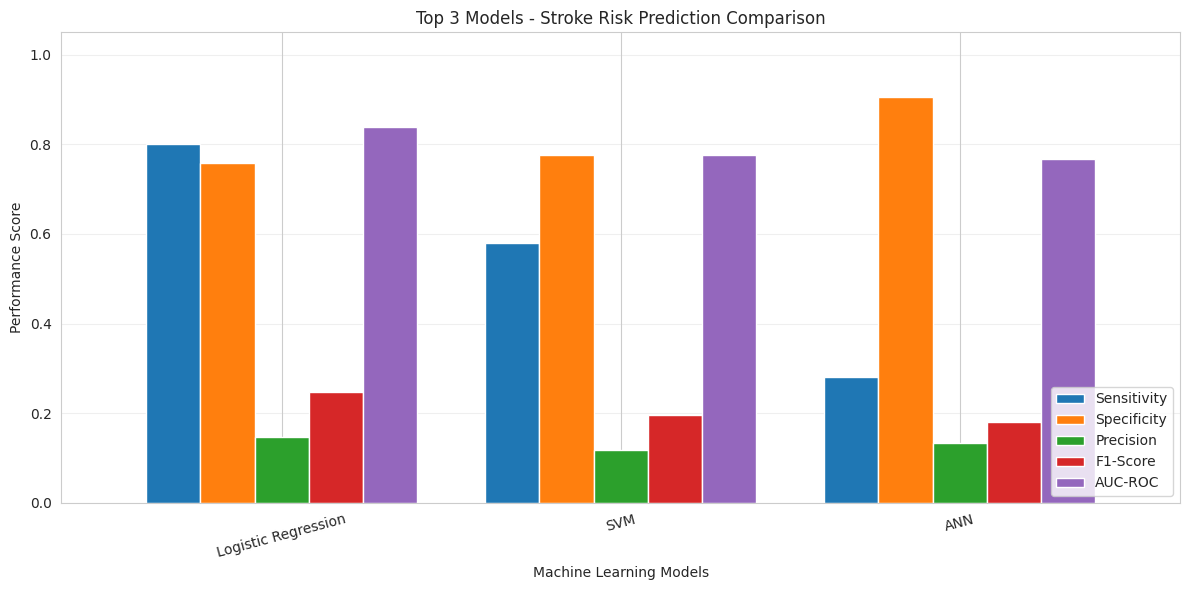

In [ ]:
plt.figure(figsize=(11, 6))

metrics = [
    'Sensitivity',
    'Specificity',
    'Precision',
    'F1-Score',
    'AUC-ROC'
]

risk_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title("Top 3 Models - Stroke Risk Prediction Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")

plt.xticks(rotation=15)
plt.ylim(0, 1.05)

plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
best_model_name = ranking_df.index[0]

best_model_results = ranking_df.iloc[0]

print("=" * 65)
print("FINAL COMPARATIVE STUDY - STROKE PREDICTION")
print("=" * 65)

print("\nBest Performing Model:", best_model_name)

print("\nPerformance Parameters:")

print("Accuracy:", round(best_model_results['Accuracy'], 4))
print("Precision:", round(best_model_results['Precision'], 4))
print("Recall:", round(best_model_results['Recall'], 4))
print("F1-Score:", round(best_model_results['F1-Score'], 4))
print("AUC-ROC:", round(best_model_results['AUC-ROC'], 4))

print("\nTOP THREE MODELS:")

for i, name in enumerate(top_3_models.index, 1):
    print(f"{i}. {name}")

print("\nCONCLUSION:")
print(
    f"Among the five evaluated machine learning models, "
    f"{best_model_name} achieved the best average ranking "
    f"based on Recall, F1-Score and AUC-ROC."
)

print(
    "The comparative analysis demonstrates the effectiveness "
    "of supervised machine learning and artificial neural "
    "networks for stroke classification."
)

print(
    "The final model selection should also consider false "
    "negatives, sensitivity and specificity."
)

print("\n" + "=" * 65)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("=" * 65)

FINAL COMPARATIVE STUDY - STROKE PREDICTION

Best Performing Model: Logistic Regression

Performance Parameters:
Accuracy: 0.7613
Precision: 0.146
Recall: 0.8
F1-Score: 0.2469
AUC-ROC: 0.8381

TOP THREE MODELS:
1. Logistic Regression
2. SVM
3. ANN

CONCLUSION:
Among the five evaluated machine learning models, Logistic Regression achieved the best average ranking based on Recall, F1-Score and AUC-ROC.
The comparative analysis demonstrates the effectiveness of supervised machine learning and artificial neural networks for stroke classification.
The final model selection should also consider false negatives, sensitivity and specificity.

EXPERIMENT COMPLETED SUCCESSFULLY!


In [ ]:
performance_df.to_csv(
    'Stroke_Model_Comparison.csv'
)

risk_df.to_csv(
    'Top_3_Stroke_Risk_Analysis.csv',
    index=False
)

files.download('Stroke_Model_Comparison.csv')

files.download('Top_3_Stroke_Risk_Analysis.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>